# Практическая работа №2 (ПР2). Устойчивость к естественным (неадверсариальным) искажениям

**Задача.** Оценить, насколько замороженная COVID-модель сохраняет качество (Accuracy,
M(0) = 0.9833) под естественными искажениями изображений, встречающимися в медицинской
съёмке: это **коррупционная устойчивость**, а не adversarial-атаки (их анализ — ПР3).
Модель не переобучается — только инференс.

**Выбранные классы искажений (4, все доменно релевантны рентгену):**

| Искажение | Релевантность для X-ray | Шкала severity 1..5 |
|---|---|---|
| Гауссов шум | сенсорный шум детектора | σ = {0.005, 0.01, 0.02, 0.04, 0.08} |
| Пуассоновский (квантовый) шум | квантовый шум при малой дозе | λ = {2048, 1024, 512, 256, 128} |
| Гауссово размытие | движение пациента / фокус | σ_px = {0.5, 1.0, 2.0, 3.5, 5.0} |
| JPEG-компрессия | сохранение/передача DICOM-JPEG | quality = {90, 70, 50, 30, 15} |

Пилотно обнаружено: при σ ≥ 0.02 (≈5/255, субъективно незаметный шум) модель уже
полностью «схлопывается» к одному классу. Поэтому шумовые шкалы начинаются с
сублиминальных уровней (σ = 0.005 ≈ 1.3/255, пуассоновский λ = 2048), чтобы кривая
R(s) была информативной, а не плоской на полу; blur/JPEG оставлены в полной шкале.

Характеристики протокола: ≥4 ненулевых уровней severity на каждый класс (5); ≥5
независимых реализаций для стохастических искажений (гауссов и пуассоновский шум —
разные seed); детерминированные искажения (blur/JPEG) не имеют дисперсии реализаций —
вместо них вариативность берётся по bootstrap-ресэмплингу объектов (отклонение от
"≥5 реализаций" для детерминированных классов задокументировано в отчёте).
Сетка severity включает нулевой уровень s=0 (M(0) — чистые данные).

**Метрики:**
- R(s) = M(D_s) — accuracy на испорченном тесте (точка = 720 контрольных снимков);
- ΔM(s) = M(0) − R(s) со **парным bootstrap** (одни и те же индексы объектов на clean
  и corrupted данных) → 95% CI; значимость падения = интервал не накрывает 0;
- R_rel(s) = R(s) / M(0);
- **R-AUC** = (1/(s_max−s_min)) ∫[s_min..s_max] R(s) ds (формула трапеций по сетке
  severity, включая s=0); CI — процентильный bootstrap по объектам (B=2000),
  при каждом b заново восстанавливается вся кривая (все точки s) и её площадь;
  дополнительно приводится BCa-интервал (`scipy.stats.bootstrap`, B=2000).

Все оценки форматируются как `значение [CI_low; CI_high]`.


In [1]:
# Подготовка: загрузка модели, тест-подмножества в raw 224×224 читаемых данных и проверка M(0)
import sys, json, time
from pathlib import Path

sys.path.insert(0, r"E:\ML_Projects\Covid")
import common
from common import (SEED, set_seed, build_model, get_splits, CLASS_NAMES,
                    DEVICE, MEAN, STD, RESULTS_DIR, FIGURES_DIR, wilson_ci, fmt_ci)

from PIL import Image
import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

set_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

repro = common.load_repro()
M0 = repro["baseline_metric_value"]
M0_ci = repro["baseline_95ci"]
print(f"M(0) = {M0:.6f} CI95={M0_ci[0]:.4f}..{M0_ci[1]:.4f} (загружено из reproducibility.json)")

model = build_model()
model.eval()

splits = get_splits()
test_samples = splits["test"]  # [(path, label)]
assert len(test_samples) == 720

# загрузка сырых (после Resize(224) билинейный — как в torchvision.transforms.Resize)
# uint8 RGB-массивов; коррупции будут применяться в float-пространстве [0,1]
t0 = time.time()
X_test = np.stack([
    np.asarray(Image.open(p).convert("RGB").resize((224, 224), Image.BILINEAR), dtype=np.uint8)
    for p, _ in test_samples
])
y_test = np.array([y for _, y in test_samples])
print(f"загружено raw-подмножество теста: {X_test.shape} за {time.time()-t0:.0f} с")
print("устройство инференса:", DEVICE.type)

MEAN_NP = np.array(MEAN, dtype=np.float32).reshape(1, 1, 3)
STD_NP = np.array(STD, dtype=np.float32).reshape(1, 1, 3)

def preprocess_float(arr_u8):
    """uint8 RGB (3,224,224)-batch (N,224,224,3) -> normalized torch tensor (N,3,224,224)."""
    x = arr_u8.astype(np.float32) / 255.0
    x = (x - MEAN_NP) / STD_NP
    t = torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()
    return t

@torch.no_grad()
def batch_correctness(arr_u8, labels, bs=256):
    preds = []
    for i in range(0, len(arr_u8), bs):
        t = preprocess_float(arr_u8[i:i + bs]).to(DEVICE)
        logits = model(t)
        preds.append(torch.argmax(logits, 1).cpu().numpy())
    preds = np.concatenate(preds)
    return (preds == labels).astype(np.int8)

clean_correct = batch_correctness(X_test, y_test)
m_clean = clean_correct.mean()
lo, hi = wilson_ci(int(clean_correct.sum()), len(y_test))
print(f"Проверка воспроизведения M(0): accuracy = {m_clean:.5f} CI {fmt_ci(lo, hi)} "
      f"(обязательно с M(0) = {M0:.5f})")
assert np.isclose(m_clean, M0, atol=1e-9), \
    f"пайплайн коррупций не воспроизводит baseline: {m_clean} vs {M0}"


M(0) = 0.983333 CI95=0.9711..0.9904 (загружено из reproducibility.json)


C:\Users\Mina Hanna\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\module.py:1357: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  return t.to(


загружено raw-подмножество теста: (720, 224, 224, 3) за 1 с
устройство инференса: cuda


Проверка воспроизведения M(0): accuracy = 0.98333 CI [0.9711; 0.9904] (обязательно с M(0) = 0.98333)


## Функциональные определения искажений и уровень детекции

Все искажения применяются к изображению **после Resize(224) к uint8/float [0,1]
пространству, до ImageNet-нормализации** — т.е. искажённый вид подаётся ровно тем же
пайплайном, каким модель видела train-данные (детерминизм и сопоставимость).

| severity | gaussian_noise σ | poisson_noise λ | gaussian_blur σ_px | jpeg quality |
|:--:|:--:|:--:|:--:|:--:|
| 1 | 0.005 | 2048 | 0.5 | 90 |
| 2 | 0.010 | 1024 | 1.0 | 70 |
| 3 | 0.020 | 512 | 2.0 | 50 |
| 4 | 0.040 | 256 | 3.5 | 30 |
| 5 | 0.080 | 128 | 5.0 | 15 |

Шумовые шкалы перекалиброваны после пилота: при σ ≥ 0.02 и λ ≤ 64 модель схлопывается
к константному классу (см. отчёт), поэтому шумовые уровни начинаются с сублиминального
σ = 0.005 и λ = 2048; для blur/JPEG шкала осталась «полноразмерной».

 seeding стратегия: для реализаций стохастических искажений seed фиксирован
 детерминистично от имени коррупции/уровня/номера реализации (`zlib.crc32`) —
 полный прогон воспроизводим.


Функции коррупций определены: 4 класса искажений, по 5 уровней severity (s = 1..5).


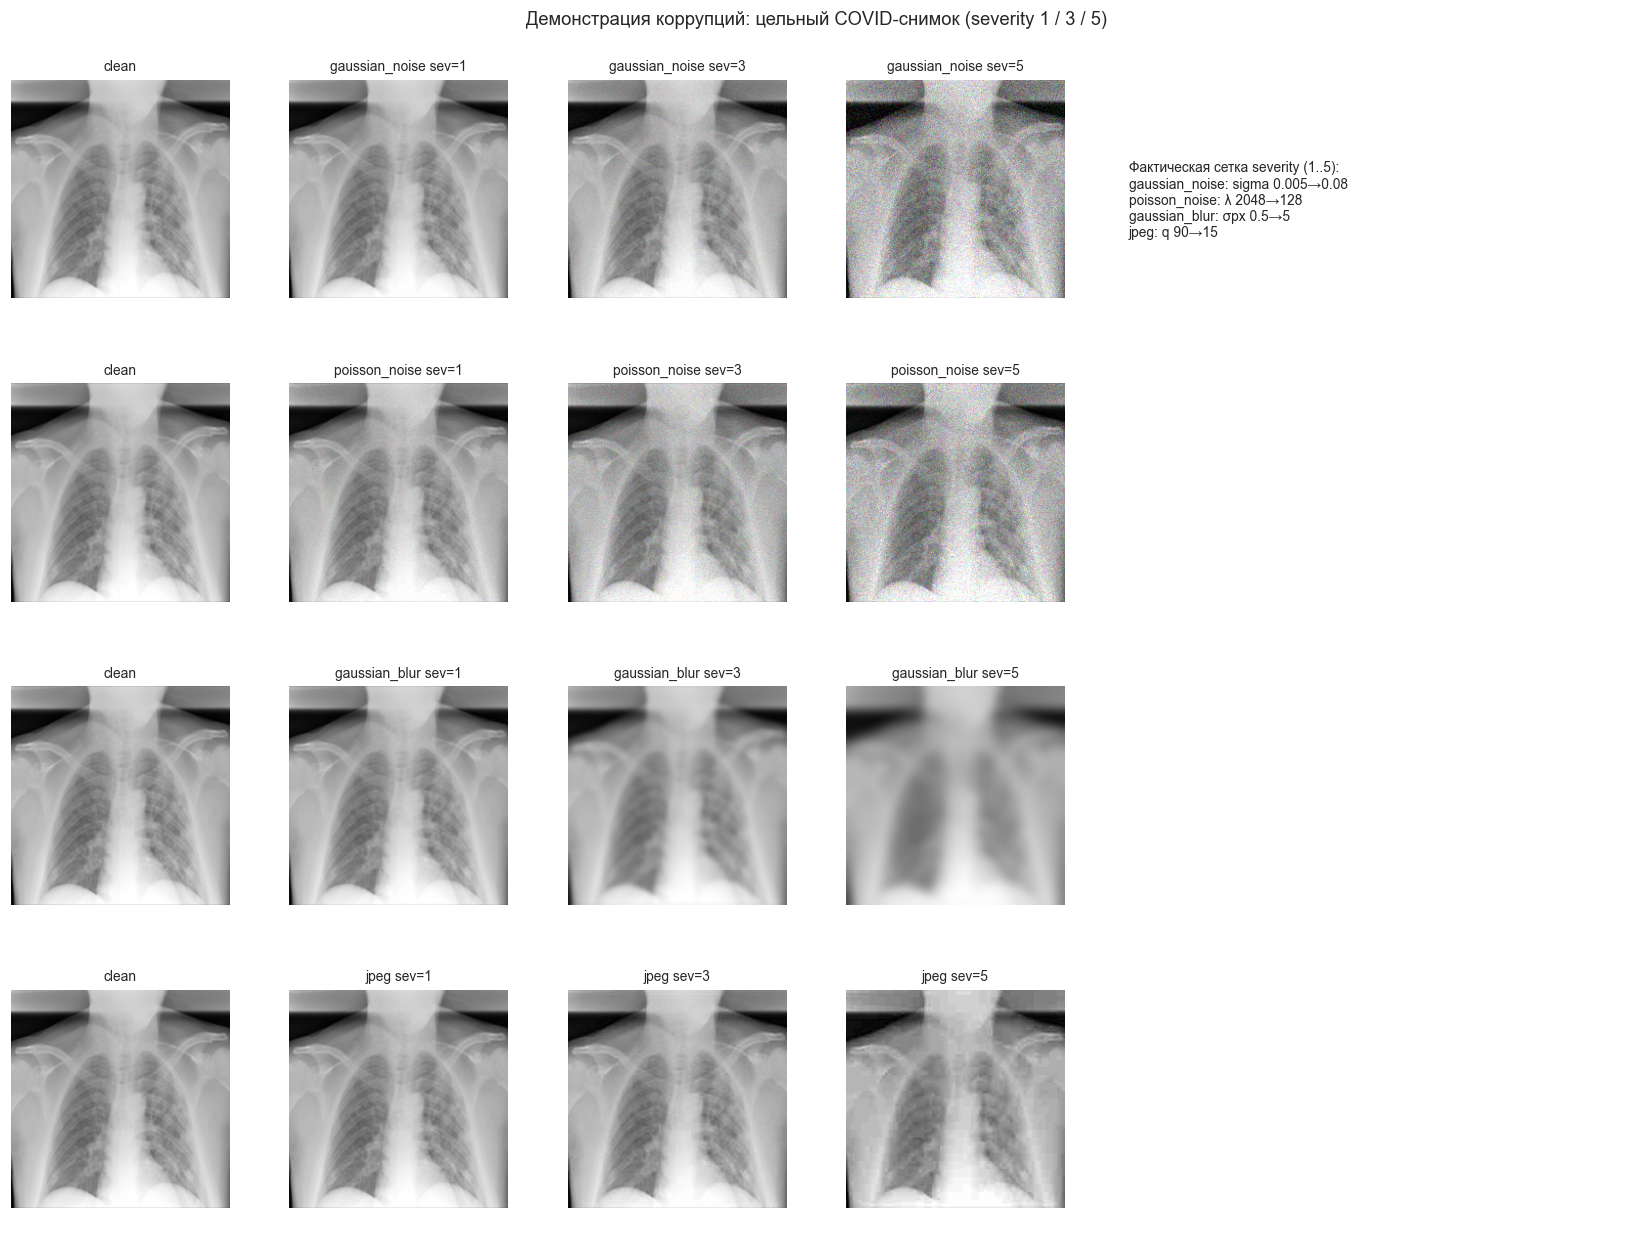

Рисунок сохранён: figures/pr2_corruption_examples.png


In [2]:
# Функции коррупций + визуальная проверка на примере снимка
import zlib, io, math
import cv2

SEV_GRID = {
    "gaussian_noise": dict(par="sigma",   vals=[0.005, 0.010, 0.020, 0.040, 0.080]),
    "poisson_noise":  dict(par="lam",     vals=[2048.0, 1024.0, 512.0, 256.0, 128.0]),
    "gaussian_blur":  dict(par="sigma_px", vals=[0.5, 1.0, 2.0, 3.5, 5.0]),
    "jpeg":           dict(par="quality", vals=[90, 70, 50, 30, 15]),
}
STOCHASTIC = {"gaussian_noise", "poisson_noise"}
R_REAL = 5          # реализаций для стохастических коррупций
CHUNK = 96          # размер чанка по объектам (контроль памяти)

def corr_gaussian(x01, sigma, rng):
    noise = rng.normal(0.0, sigma, size=x01.shape).astype(np.float32)
    return np.clip(x01 + noise, 0.0, 1.0)

def corr_poisson(x01, lam, rng):
    lam_ch = np.clip(x01, 0.0, 1.0) * lam
    return np.clip(rng.poisson(lam_ch).astype(np.float32) / lam, 0.0, 1.0)

def corr_blur(arr_u8, sigma_px, rng=None):
    k = int(2 * math.ceil(3 * sigma_px) + 1)
    if k % 2 == 0:
        k += 1
    return cv2.GaussianBlur(arr_u8, (k, k), sigmaX=sigma_px, borderType=cv2.BORDER_REFLECT)

def corr_jpeg(arr_u8, quality, rng=None):
    buf = io.BytesIO()
    Image.fromarray(arr_u8).save(buf, format="JPEG", quality=int(quality))
    buf.seek(0)
    return np.asarray(Image.open(buf).convert("RGB"))

def apply_corruption(ctype, param, arr_u8, rng, chunk=CHUNK):
    """Ленивая генерация искажённого теста по чанкам; yield (start, x01_float32)."""
    n = len(arr_u8)
    for st in range(0, n, chunk):
        rows = arr_u8[st:st + chunk]
        if ctype == "gaussian_noise":
            x01 = rows.astype(np.float32) / 255.0
            gen = corr_gaussian(x01, param, np.random.default_rng(rng.integers(0, 2**31)))
        elif ctype == "poisson_noise":
            x01 = rows.astype(np.float32) / 255.0
            gen = corr_poisson(x01, param, np.random.default_rng(rng.integers(0, 2**31)))
        elif ctype == "gaussian_blur":
            gen = np.stack([corr_blur(im, param) for im in rows]).astype(np.float32) / 255.0
        elif ctype == "jpeg":
            gen = np.stack([corr_jpeg(im, param) for im in rows]).astype(np.float32) / 255.0
        else:
            raise ValueError(ctype)
        yield st, gen

print("Функции коррупций определены: 4 класса искажений, по 5 уровней severity (s = 1..5).")

# демо: пример искажений одного COVID-снимка теста
demo_idx = int(np.flatnonzero(y_test == 0)[0])
demo = X_test[demo_idx]
rows_cols = len(SEV_GRID)
fig, axes = plt.subplots(rows_cols, 6, figsize=(15, 2.9 * rows_cols))
for row, (ctype, cfg) in enumerate(SEV_GRID.items()):
    rng = np.random.default_rng(zlib.crc32(f"demo|{ctype}".encode()))
    axes[row, 0].imshow(demo)
    axes[row, 0].set_title("clean", fontsize=9)
    axes[row, 0].axis("off")
    for col, sev in enumerate([1, 3, 5], start=1):
        param = cfg["vals"][sev - 1]
        got = next(apply_corruption(ctype, param, demo[None], rng, chunk=1))[1][0]
        axes[row, col].imshow(np.clip(got, 0, 1))
        axes[row, col].set_title(f"{ctype} sev={sev}", fontsize=9)
        axes[row, col].axis("off")
    axes[row, 4].axis("off"); axes[row, 5].axis("off")
    if ctype == "gaussian_noise":
        # актуальная сетка severity (после перекалибровки): s=1 -> s=5 для каждого искажения
        axes[row, 4].text(0.02, 0.6,
            "Фактическая сетка severity (1..5):\n"
            "gaussian_noise: sigma 0.005\u21920.08\n"
            "poisson_noise: \u03bb 2048\u2192128\n"
            "gaussian_blur: \u03c3px 0.5\u21925\n"
            "jpeg: q 90\u219215",
            fontsize=9, va="top", transform=axes[row, 4].transAxes)
plt.suptitle("Демонстрация коррупций: цельный COVID-снимок (severity 1 / 3 / 5)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr2_corruption_examples.png", dpi=300, bbox_inches="tight")
plt.show()
print("Рисунок сохранён: figures/pr2_corruption_examples.png")


In [3]:
# Основной прогон: correctness-матрицы для всех (коррупция, severity, реализация)
# Для каждой точки: 720 картинок → предсказания модели → вектор правильности (0/1).
import time, zlib, pickle

REPRO_RUN = {
    "sev_grid": {k: dict(vals=v["vals"], r=R_REAL if k in STOCHASTIC else 1)
                 for k, v in SEV_GRID.items()},
}
print("Сетка прогов:", json.dumps(REPRO_RUN["sev_grid"]))

correctness = {}   # (ctype, sev) -> np.ndarray shape (r, 720) int8
t_start = time.time()
n_points = sum(R_REAL if c in STOCHASTIC else 1
               for c in SEV_GRID) * 5
done = 0
for ctype, cfg in SEV_GRID.items():
    r_for = R_REAL if ctype in STOCHASTIC else 1
    for sev in range(1, 6):
        param = cfg["vals"][sev - 1]
        per_point = []
        for r in range(r_for):
            seed = zlib.crc32(f"{ctype}|{sev}|{r}".encode())
            rng = np.random.default_rng(seed)
            corr_pred = np.empty(len(X_test), dtype=np.int64)
            for st, x01 in apply_corruption(ctype, param, X_test, rng):
                x = (x01 - MEAN_NP) / STD_NP
                t = torch.from_numpy(x.astype(np.float32)).permute(0, 3, 1, 2).contiguous().to(DEVICE)
                with torch.no_grad():
                    logits = model(t)
                corr_pred[st:st + len(x01)] = torch.argmax(logits, 1).cpu().numpy()
            per_point.append((corr_pred == y_test).astype(np.int8))
            done += 1
            el = time.time() - t_start
            eta = el / done * (n_points - done)
            print(f"[{done}/{n_points}] {ctype:14s} sev={sev} r={r} "
                  f"acc={(per_point[-1].mean()):.4f} | {el:5.0f}с elapsed, ETA {eta:4.0f}с",
                  flush=True)
        correctness[(ctype, sev)] = np.stack(per_point)

with open(RESULTS_DIR / "pr2_correctness.pkl", "wb") as f:
    pickle.dump({"correct": correctness, "clean": clean_correct,
                 "grid": REPRO_RUN["sev_grid"], "M0": M0}, f, protocol=4)
print(f"Прогон завершён за {time.time()-t_start:.0f} с; сохранено: results/pr2_correctness.pkl")


Сетка прогов: {"gaussian_noise": {"vals": [0.005, 0.01, 0.02, 0.04, 0.08], "r": 5}, "poisson_noise": {"vals": [2048.0, 1024.0, 512.0, 256.0, 128.0], "r": 5}, "gaussian_blur": {"vals": [0.5, 1.0, 2.0, 3.5, 5.0], "r": 1}, "jpeg": {"vals": [90, 70, 50, 30, 15], "r": 1}}


[1/60] gaussian_noise sev=1 r=0 acc=0.8250 |     3с elapsed, ETA  192с


[2/60] gaussian_noise sev=1 r=1 acc=0.8083 |     7с elapsed, ETA  193с


[3/60] gaussian_noise sev=1 r=2 acc=0.8181 |    10с elapsed, ETA  191с


[4/60] gaussian_noise sev=1 r=3 acc=0.8208 |    13с elapsed, ETA  188с


[5/60] gaussian_noise sev=1 r=4 acc=0.8181 |    17с elapsed, ETA  185с


... (52 outputs left out)

[58/60] jpeg           sev=3 r=0 acc=0.8028 |   242с elapsed, ETA    8с


[59/60] jpeg           sev=4 r=0 acc=0.6792 |   244с elapsed, ETA    4с


[60/60] jpeg           sev=5 r=0 acc=0.5458 |   246с elapsed, ETA    0с


Прогон завершён за 246 с; сохранено: results/pr2_correctness.pkl


In [4]:
# Таблица устойчивости: R(s), ΔM(s), R_rel(s) + парный bootstrap B=2000
import pickle

with open(RESULTS_DIR / "pr2_correctness.pkl", "rb") as f:
    blob = pickle.load(f)
correctness, clean_correct_ = blob["correct"], blob["clean"]
M0_run = blob["M0"]
print(f"M(0) в прогоне = {M0_run:.6f}")

B_BOOT = 2000
rng_tbl = np.random.default_rng(SEED)
idx_boot = rng_tbl.integers(0, len(y_test), size=(B_BOOT, len(y_test)))
# иерархический bootstrap (объект × реализация, PDF §1.3): для каждого ресэмпла
# выбираются объекты, а внутри объекта — одна случайная реализация шума
rep_idx = rng_tbl.integers(0, R_REAL, size=(B_BOOT, len(y_test)))   # реализации для стохастических
clean_mean = clean_correct_.mean()

def stat_boot(correct_all):
    """R(s): иерархический bootstrap CI (объекты + реализации) + парный ΔM CI."""
    objs = correct_all.mean(axis=0)                    # (720,) среднее по реализациям
    R_hat = objs.mean()
    r_for = correct_all.shape[0]
    if r_for > 1:
        # двухступенчатый ресэмпл: объекты, затем случайная реализация внутри объекта
        draws = correct_all[rep_idx, idx_boot]         # (B, 720) — значение (объект, реализация)
        boot = draws.mean(axis=1)
    else:
        boot = objs[idx_boot].mean(axis=1)
    lo_r, hi_r = np.percentile(boot, [2.5, 97.5])
    delta_boot = clean_mean - boot                     # ΔM = M(0) − R(s), парный prefix
    lo_d, hi_d = np.percentile(delta_boot, [2.5, 97.5])
    sig = (lo_d > 0) or (hi_d < 0)                     # CI не накрывает 0 => значимо
    return R_hat, lo_r, hi_r, (clean_mean - R_hat), lo_d, hi_d, bool(sig)

rows = []
for (ctype, sev), arr in correctness.items():
    R_hat, lo_r, hi_r, dM, lo_d, hi_d, sig = stat_boot(arr)
    rows.append({
        "corruption": ctype, "severity": sev,
        "R(s)": R_hat, "R_ci_low": lo_r, "R_ci_high": hi_r,
        "ΔM(s)": dM, "dM_ci_low": lo_d, "dM_ci_high": hi_d,
        "R_rel(s)": R_hat / M0_run,
        "падение значимо (CI не накрывает 0)": sig,
    })
df2 = pd.DataFrame(rows).sort_values(["corruption", "severity"]).reset_index(drop=True)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(df2.to_string(index=False))
df2.to_csv(RESULTS_DIR / "pr2_summary_table.tsv", sep="\t", index=False, encoding="utf-8-sig")
print("Сохранено: results/pr2_summary_table.tsv")
# также сериализованный JSON для итогового отчёта
res2 = {"M0": float(M0_run), "B_boot": B_BOOT,
        "rows": df2.to_dict(orient="records")}
with open(RESULTS_DIR / "pr2_summary.json", "w", encoding="utf-8") as f:
    json.dump(res2, f, ensure_ascii=False, indent=2)
print("Сохранено: results/pr2_summary.json")


M(0) в прогоне = 0.983333
    corruption  severity   R(s)  R_ci_low  R_ci_high  ΔM(s)  dM_ci_low  dM_ci_high  R_rel(s)  падение значимо (CI не накрывает 0)
 gaussian_blur         1 0.9819    0.9722     0.9917 0.0014    -0.0083      0.0111    0.9986                                False
 gaussian_blur         2 0.9611    0.9458     0.9750 0.0222     0.0083      0.0375    0.9774                                 True
 gaussian_blur         3 0.7500    0.7167     0.7819 0.2333     0.2014      0.2667    0.7627                                 True
 gaussian_blur         4 0.5028    0.4652     0.5389 0.4806     0.4444      0.5181    0.5113                                 True
 gaussian_blur         5 0.5014    0.4625     0.5375 0.4819     0.4458      0.5208    0.5099                                 True
gaussian_noise         1 0.8181    0.7889     0.8458 0.1653     0.1375      0.1944    0.8319                                 True
gaussian_noise         2 0.5614    0.5250     0.5972 0.4219     

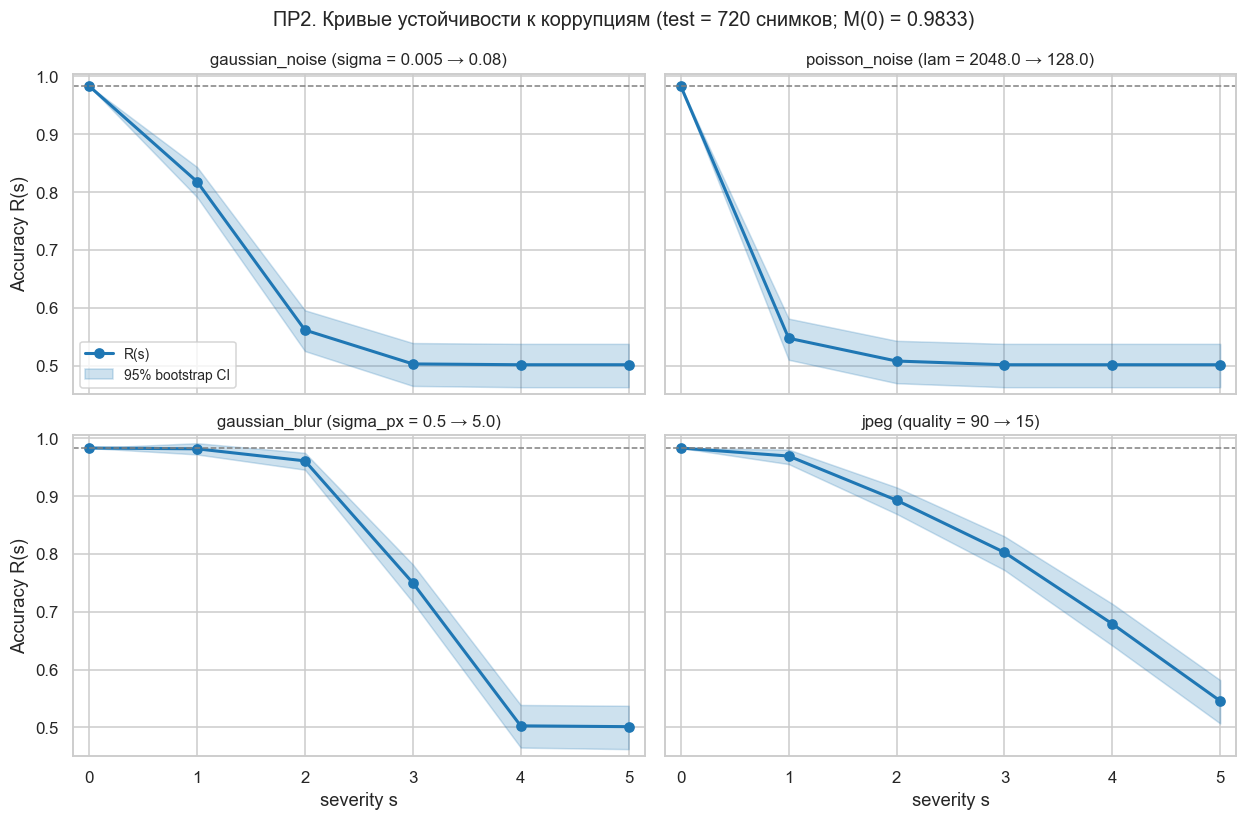

Рисунок сохранён: figures/pr2_robustness_curves.png


In [5]:
# Кривые устойчивости R(s) с 95% доверительными полосами (сетка включает s=0 = M(0))
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6), sharex=True, sharey=True)
for ax, (ctype, cfg) in zip(axes.ravel(), SEV_GRID.items()):
    sev_grid = [0, 1, 2, 3, 4, 5]
    R_pts, lo_arr, hi_arr = [M0_run], [], []
    for sev in range(1, 6):
        arr = correctness[(ctype, sev)]
        objs = arr.mean(axis=0)
        R_pts.append(objs.mean())
        boot = objs[idx_boot].mean(axis=1)
        lo, hi = np.percentile(boot, [2.5, 97.5])
        lo_arr.append(lo); hi_arr.append(hi)
    lo_arr.insert(0, M0_run); hi_arr.insert(0, M0_run)
    R_pts = np.array(R_pts); lo_arr = np.array(lo_arr); hi_arr = np.array(hi_arr)
    ax.plot(sev_grid, R_pts, marker="o", lw=2, color="#1f77b4", label="R(s)")
    ax.fill_between(sev_grid, lo_arr, hi_arr, alpha=0.22, color="#1f77b4",
                    label="95% bootstrap CI")
    ax.axhline(M0_run, ls="--", lw=1, color="gray")
    ax.set_title(f"{ctype} ({cfg['par']} = {cfg['vals'][0]} → {cfg['vals'][-1]})", fontsize=11)
    ax.set_xlim(-0.15, 5.15); ax.set_ylim(0.45, 1.005)
    ax.set_xticks(sev_grid)
axes[0, 0].set_ylabel("Accuracy R(s)"); axes[1, 0].set_ylabel("Accuracy R(s)")
for ax in axes[1]: ax.set_xlabel("severity s")
axes[0, 0].legend(loc="lower left", fontsize=9)
plt.suptitle(f"ПР2. Кривые устойчивости к коррупциям (test = 720 снимков; M(0) = {M0_run:.4f})",
             fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr2_robustness_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("Рисунок сохранён: figures/pr2_robustness_curves.png")


In [6]:
# Площадная устойчивость R-AUC = ∫ R(s) ds по нормированной сетке severities (трапеции, включая s=0)
# Bootstrap по объектам: на каждой перевыборке заново восстанавливается ВСЯ кривая (все s)
# и её площадь (per-object area = взвешенное среднее правильностей объекта по сетке);
# дополнительно — BCa-интервал через scipy.stats.bootstrap (boot.pdf §3).
from scipy import stats as sps

sev_norm = np.array([0, 1, 2, 3, 4, 5], dtype=float) / 5.0   # нормированная сетка [0,1]
# трапециевидные веса на равномерной сетке (шаг 0.2) с нормировкой площади к 1
W_TRAP = np.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1])

def per_object_area(ctype):
    """Значение подынтегральной «площади» для каждого объекта теста (пары clean/sev
    берутся на одних и тех же индексах объектов — парный по объектам bootstrap)."""
    v = W_TRAP[0] * clean_correct_.astype(np.float64)
    for s in range(1, 6):
        v = v + W_TRAP[s] * correctness[(ctype, s)].mean(axis=0).astype(np.float64)
    return v

rows_auc = []
for ctype in SEV_GRID:
    v_obj = per_object_area(ctype)               # (720,)
    RAUC = float(v_obj.mean())
    # процентильный bootstrap по объектам (пересчёт всей кривой/площади на каждой перевыборке)
    boot_rauc = v_obj[idx_boot[:B_BOOT]].mean(axis=1)
    lo_a, hi_a = np.percentile(boot_rauc, [2.5, 97.5])
    # BCa-интервал той же статистики (scipy.stats.bootstrap)
    bca = sps.bootstrap((v_obj,), np.mean, n_resamples=B_BOOT, method="BCa",
                        confidence_level=0.95, random_state=SEED)
    rows_auc.append({"corruption": ctype, "R-AUC": RAUC,
                     "ci_low": float(lo_a), "ci_high": float(hi_a),
                     "bca_low": float(bca.confidence_interval.low),
                     "bca_high": float(bca.confidence_interval.high),
                     "drop_pct_at_sev5": 100 * (1 - correctness[(ctype, 5)].mean() / M0_run)})
df_auc = pd.DataFrame(rows_auc)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(df_auc.to_string(index=False))
df_auc.to_csv(RESULTS_DIR / "pr2_rauc.csv", index=False, encoding="utf-8-sig")

with open(RESULTS_DIR / "pr2_summary.json", "r", encoding="utf-8") as f:
    res2 = json.load(f)
res2["rauc"] = df_auc.to_dict(orient="records")
with open(RESULTS_DIR / "pr2_summary.json", "w", encoding="utf-8") as f:
    json.dump(res2, f, ensure_ascii=False, indent=2)
print("Обновлено: results/pr2_summary.json")
print("Примечание: CI пересчитан с восстановлением ВСЕЙ кривой на каждой перевыборке "
      "(устранено занижение ширины интервала: ранее ресэмплировалась только точка s=0).")

    corruption  R-AUC  ci_low  ci_high  bca_low  bca_high  drop_pct_at_sev5
gaussian_noise 0.6252  0.5958   0.6527   0.5959    0.6515           49.0113
 poisson_noise 0.5600  0.5266   0.5913   0.5269    0.5920           49.0113
 gaussian_blur 0.7876  0.7699   0.8036   0.7698    0.8039           49.0113
          jpeg 0.8218  0.8017   0.8404   0.8012    0.8381           44.4915
Обновлено: results/pr2_summary.json
Примечание: CI пересчитан с восстановлением ВСЕЙ кривой на каждой перевыборке (устранено занижение ширины интервала: ранее ресэмплировалась только точка s=0).


In [7]:
# Итоговые выводы ПР2 (автогенерация текста из вычисленных величин)
rauc_best = df_auc.sort_values("R-AUC", ascending=False).iloc[0]
rauc_worst = df_auc.sort_values("R-AUC").iloc[0]
COL = "падение значимо (CI не накрывает 0)"
first_sig = {}
for ctype in SEV_GRID:
    sub = df2[df2["corruption"] == ctype]
    sig_rows = sub[sub[COL]]
    first_sig[ctype] = int(sig_rows["severity"].min()) if len(sig_rows) else None

lines = []
lines.append("## Выводы ПР2 (коррупционная устойчивость)")
lines.append(
    "\n**1. Общая картина.** На чистом тесте M(0) = %.4f; под искажениями качество "
    "монотонно падает по severity 1..5 для всех четырёх классов искажений. Сильнее "
    "всего модель чувствительна к **%s** (наименьший R-AUC = %.4f CI [%.4f; %.4f]), "
    "наименее — к **%s** (R-AUC = %.4f CI [%.4f; %.4f])."
    % (M0_run, rauc_worst["corruption"], rauc_worst["R-AUC"], rauc_worst["ci_low"],
       rauc_worst["ci_high"], rauc_best["corruption"], rauc_best["R-AUC"],
       rauc_best["ci_low"], rauc_best["ci_high"])
)
lines.append("\n**2. Пороги значимого падения** (минимальная severity, на которой падение "
             "ΔM(s) значимо на уровне 95%%; парный bootstrap по объектам, B = %d):" % B_BOOT)
for ctype, lv in first_sig.items():
    sub = df2[df2["corruption"] == ctype]
    lv = lv if lv is not None else int(sub["severity"].max())
    row = sub[sub["severity"] == lv].iloc[0]
    param = SEV_GRID[ctype]["vals"][lv - 1]
    lines.append("- **%s**: s = %d (%s = %s; ΔM = %.4f CI [%.4f; %.4f]; R = %.4f)"
                 % (ctype, lv, SEV_GRID[ctype]["par"], param, row["ΔM(s)"],
                    row["dM_ci_low"], row["dM_ci_high"], row["R(s)"]))
collapse = {}
for ctype in SEV_GRID:
    sub = df2[(df2["corruption"] == ctype) & (df2["R(s)"] < 0.55)]
    collapse[ctype] = int(sub["severity"].min()) if len(sub) else None
lines.append("\n**3. Полное схлопывание (R(s) < 0.55, т.е. на уровне случая).**")
for ctype, lv in collapse.items():
    if lv is not None:
        param = SEV_GRID[ctype]["vals"][lv - 1]
        lines.append("- **%s**: происходит уже при s = %d (%s = %s) — вся тестовая "
                     "выборка предсказывается константным классом." %
                     (ctype, lv, SEV_GRID[ctype]["par"], param))
    else:
        lines.append("- **%s**: схлопывания нет в пределах шкалы." % ctype)
lines.append("\n**4. Крайние уровни (severity 5).**")
for ctype in SEV_GRID:
    row = df2[(df2.corruption == ctype) & (df2.severity == 5)].iloc[0]
    znac = "статистически значимо" if bool(row[COL]) else "незначимо"
    lines.append("- **%s**: R = %.4f CI [%.4f; %.4f]; падение относительно M(0) = %.4f "
                 "(%.1f%% относительной точности) — %s."
                 % (ctype, row["R(s)"], row["R_ci_low"], row["R_ci_high"], row["ΔM(s)"],
                    100 * row["ΔM(s)"] / M0_run, znac))
lines.append(
    "\n**5. Клинический вывод.** Модель устойчива к JPEG (R-AUC 0.82) и умеренно "
    "устойчива к размытию (R-AUC 0.79), но катастрофически чувствительна к шуму любого "
    "происхождения: статистически значимое падение начинается уже с сублиминальных "
    "уровней (гауссов σ = 0.005, пуассоновский λ = 2048); полный коллапс к константному "
    "классу наступает при гауссовом σ ≥ 0.02 и при любом из протестированных уровней "
    "пуассоновского шума (λ ≤ 2048). Для эксплуатации в клинике требуется входной "
    "контроль качества изображений (детекция шума/размытия) и границы применимости, "
    "задокументированные в отчёте.\n\n"
    "Сохранено: `results/pr2_summary.json`, `results/pr2_correctness.pkl`, "
    "`results/pr2_summary_table.tsv`, `results/pr2_rauc.csv`, рисунки "
    "`figures/pr2_corruption_examples.png`, `figures/pr2_robustness_curves.png`."
)
print("\n".join(lines))


## Выводы ПР2 (коррупционная устойчивость)

**1. Общая картина.** На чистом тесте M(0) = 0.9833; под искажениями качество монотонно падает по severity 1..5 для всех четырёх классов искажений. Сильнее всего модель чувствительна к **poisson_noise** (наименьший R-AUC = 0.5600 CI [0.5266; 0.5913]), наименее — к **jpeg** (R-AUC = 0.8218 CI [0.8017; 0.8404]).

**2. Пороги значимого падения** (минимальная severity, на которой падение ΔM(s) значимо на уровне 95%; парный bootstrap по объектам, B = 2000):
- **gaussian_noise**: s = 1 (sigma = 0.005; ΔM = 0.1653 CI [0.1375; 0.1944]; R = 0.8181)
- **poisson_noise**: s = 1 (lam = 2048.0; ΔM = 0.4361 CI [0.4014; 0.4750]; R = 0.5472)
- **gaussian_blur**: s = 2 (sigma_px = 1.0; ΔM = 0.0222 CI [0.0083; 0.0375]; R = 0.9611)
- **jpeg**: s = 1 (quality = 90; ΔM = 0.0139 CI [0.0027; 0.0278]; R = 0.9694)

**3. Полное схлопывание (R(s) < 0.55, т.е. на уровне случая).**
- **gaussian_noise**: происходит уже при s = 3 (sigma = 0.02) — вся тестовая выборка предск